In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv('/home/b/Downloads/student_scores.csv.xls')
data.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [19]:
data

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30
5,1.5,20
6,9.2,88
7,5.5,60
8,8.3,81
9,2.7,25


In [3]:
data.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 528.0 bytes


In [5]:
data.isnull().sum()

Hours     0
Scores    0
dtype: int64

In [6]:
# splitting the data into attributes and label
x = data[['Hours']]
y = data[['Scores']]

In [7]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
predictions = model.predict([[9]])
print(predictions)

[[89.96559574]]


/home/b/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [16]:
hours = 9
prediction = model.predict([[hours]])
print(f"if a student studies for {hours} hours,")
print(f"the predicted score is {prediction.ravel()[0]:.2f}")

if a student studies for 9 hours,
the predicted score is 89.97


/home/b/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [12]:
predictions = model.predict([[4],[6],[8]])
print(predictions)

[[41.55520497]
 [60.91936128]
 [80.28351759]]


/home/b/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [13]:
from sklearn.metrics import r2_score

y_pred = model.predict(x_test)

score = r2_score(y_test, y_pred)

print(score)

0.9678055545167994


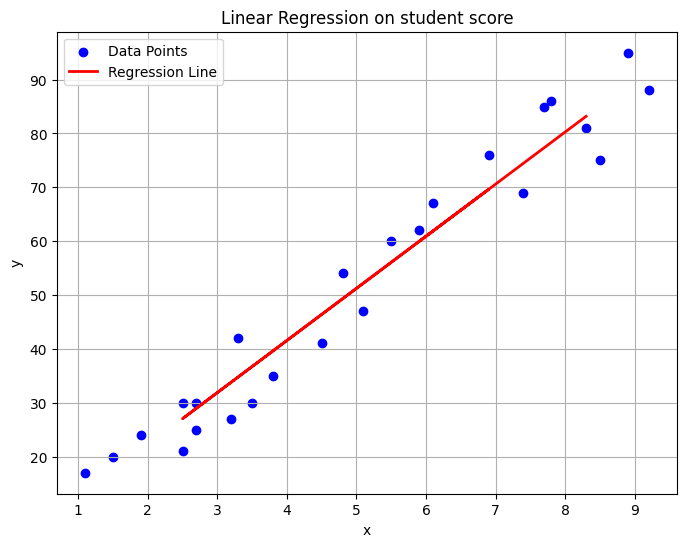

In [18]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(8,6))
plt.scatter(x.to_numpy().flatten(), y, color='blue', label='Data Points')
plt.plot(x_test, y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('Linear Regression on student score')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()